### ***1) Introduction***
### ***1.1 Imports Libraries*** 

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Preprocessing 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model Selection & Metrics 
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix, 
                             roc_auc_score, precision_recall_curve, 
                             f1_score, recall_score, precision_score, accuracy_score)

# Models 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# Configuration 
sns.set_style("whitegrid") 
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


### ***1.2 Load Dataset***

In [52]:
try:
    df = pd.read_csv('./Data_Stroke/stroke_data_raw.csv')
    print("Dataset loaded successfully.")
    print(f"Shape: {df.shape}")
    df.info()
    display(df.head())
except FileNotFoundError:
    print("File not found. Please check the path.")

Dataset loaded successfully.
Shape: (5110, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [53]:
df.drop(columns=['id'], inplace=True)
display(df.head())

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [54]:
def convert_cat(df, features):
    """Convert type of feature => Categorical"""
    for feature in features:
        df[feature] = df[feature].astype('category')

features = ['gender', 'hypertension', 'heart_disease','ever_married', 'work_type', 'Residence_type','smoking_status','stroke']
convert_cat(df , features)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   gender             5110 non-null   category
 1   age                5110 non-null   float64 
 2   hypertension       5110 non-null   category
 3   heart_disease      5110 non-null   category
 4   ever_married       5110 non-null   category
 5   work_type          5110 non-null   category
 6   Residence_type     5110 non-null   category
 7   avg_glucose_level  5110 non-null   float64 
 8   bmi                4909 non-null   float64 
 9   smoking_status     5110 non-null   category
 10  stroke             5110 non-null   category
dtypes: category(8), float64(3)
memory usage: 161.0 KB


### ***1.3. Missing Values***

In [55]:
# Missing Values
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


/var/folders/5n/q_dvq0yj0p74ffh__0vftbfm0000gn/T/ipykernel_65392/378229033.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  bmi_df['bmi'].fillna(-5, inplace=True);


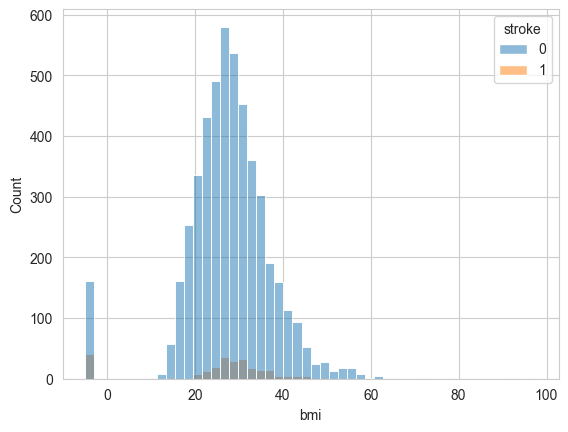

In [56]:
bmi_df = df.copy()
bmi_df['bmi'].fillna(-5, inplace=True);
sns.histplot(data=bmi_df, x='bmi',hue='stroke',bins= 50);

### ***2) Data Visualization***
### ***2.1. Corr Heat Map*** 

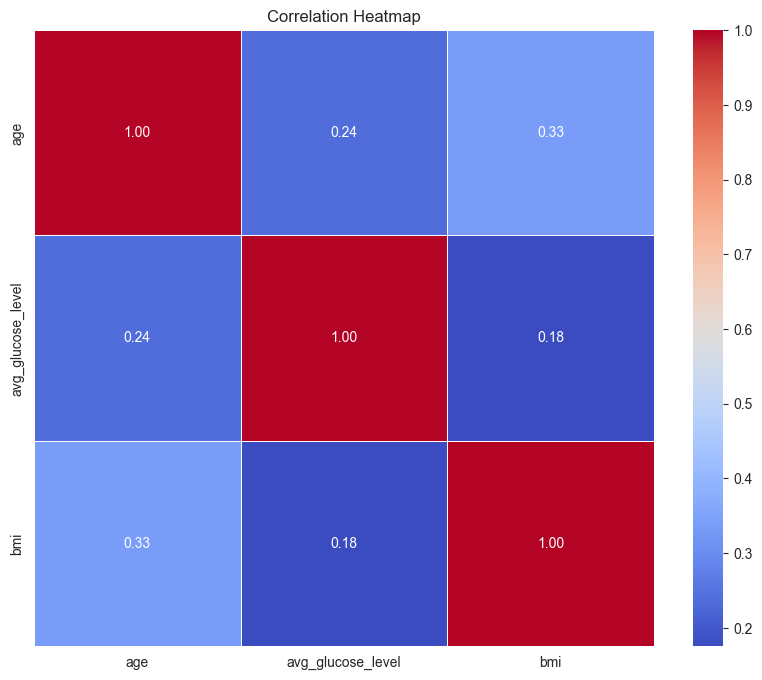

In [57]:
# Corr Heat Map
plt.figure(figsize=(10, 8))
# Chỉ lấy các cột số để tính correlation
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title("Correlation Heatmap")
plt.show()

### ***2.2. Count Plot*** 

/var/folders/5n/q_dvq0yj0p74ffh__0vftbfm0000gn/T/ipykernel_65392/4009519923.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stroke', data=df, palette='pastel')


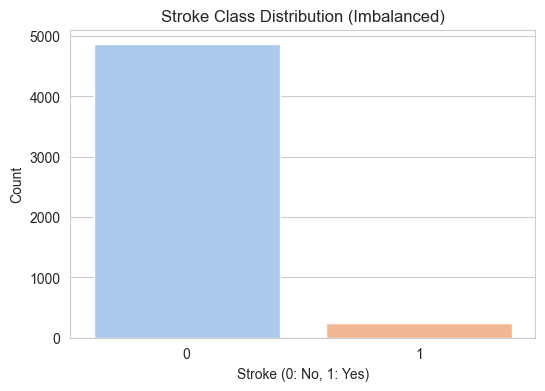

stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64


In [58]:
# Count Plot (Target Variable Balance)
plt.figure(figsize=(6, 4))
sns.countplot(x='stroke', data=df, palette='pastel')
plt.title("Stroke Class Distribution (Imbalanced)")
plt.xlabel("Stroke (0: No, 1: Yes)")
plt.ylabel("Count")
plt.show()

print(df['stroke'].value_counts(normalize=True))

### ***2.3. Distibution Plot***

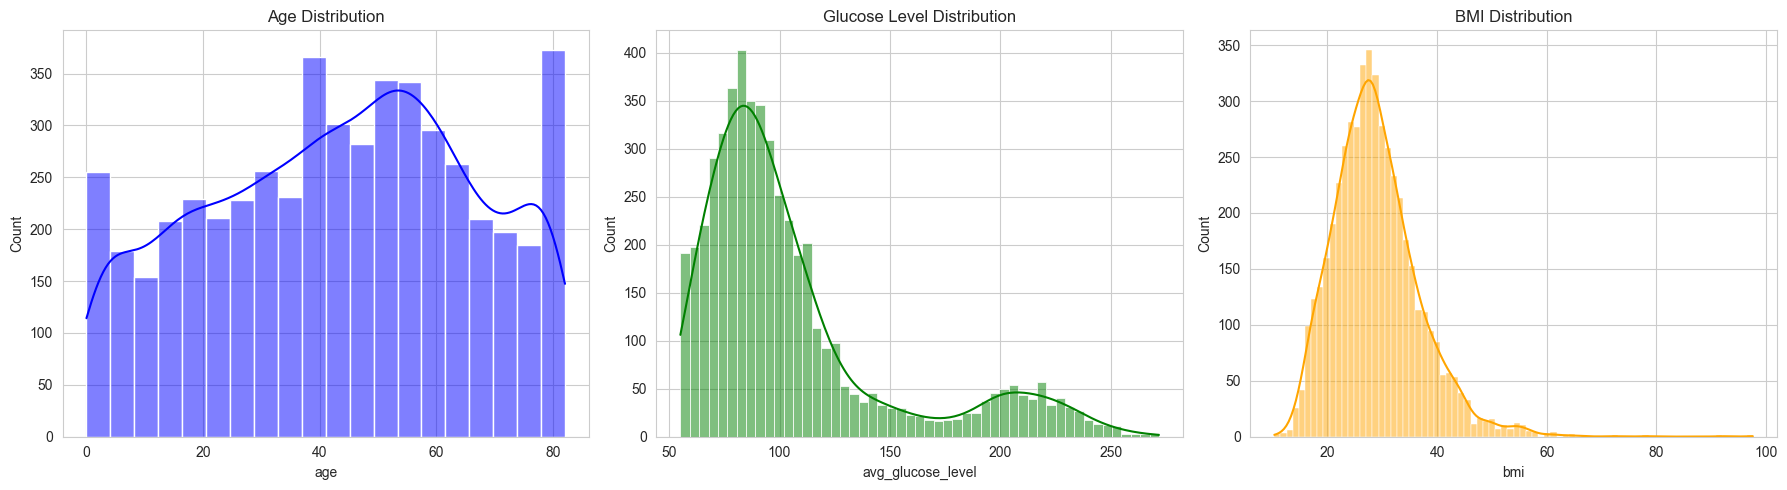

In [59]:
# Distribution Plot (Numerical Features)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['age'], kde=True, color='blue', ax=axes[0])
axes[0].set_title('Age Distribution')

sns.histplot(df['avg_glucose_level'], kde=True, color='green', ax=axes[1])
axes[1].set_title('Glucose Level Distribution')

sns.histplot(df['bmi'].dropna(), kde=True, color='orange', ax=axes[2])
axes[2].set_title('BMI Distribution')

plt.tight_layout()
plt.show()

### ***2.4. Scatter Plot***

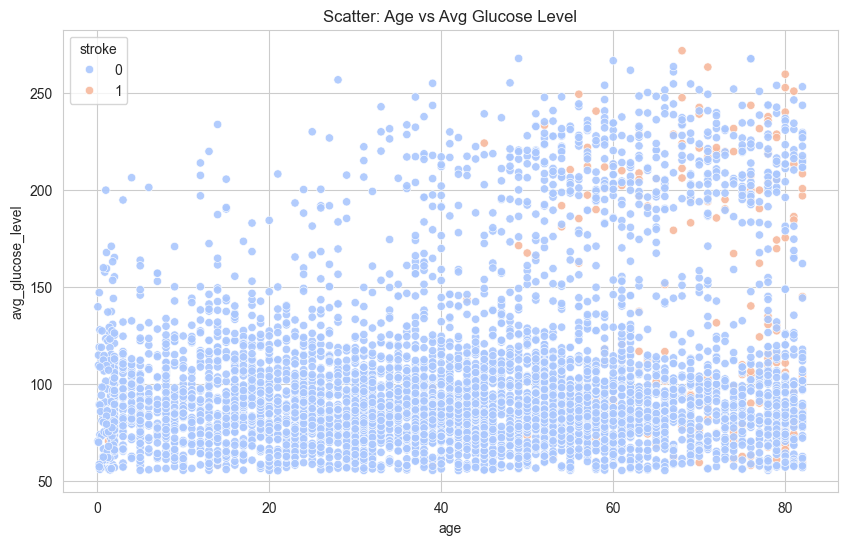

In [60]:
# Scatter Plot (Age vs Glucose by Stroke)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='avg_glucose_level', hue='stroke', data=df, alpha=0.9, palette='coolwarm')
plt.title("Scatter: Age vs Avg Glucose Level")
plt.show()

### ***2.5. Pair Plot***

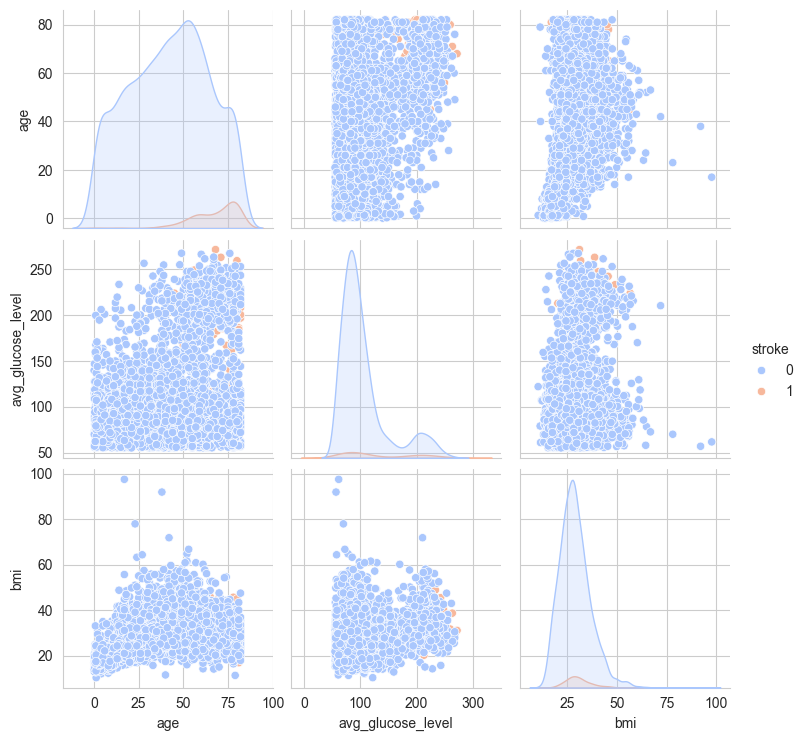

In [61]:
# Pair Plot
# Chọn một số cột quan trọng 
cols_to_plot = ['age', 'avg_glucose_level', 'bmi', 'stroke']
sns.pairplot(df[cols_to_plot], hue='stroke', palette='coolwarm', diag_kind='kde')
plt.show()

### ***3) Data Preprocessing***
### ***3.1. X and Y Splitting***

In [62]:
# X and Y Splitting
X = df.drop('stroke', axis=1)
y = df['stroke']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (5110, 10)
Target (y) shape: (5110,)


### ***3.2. Column Transformator and OneHotEncoder***

In [63]:
# Column Transformator and OneHotEncoder (Pipeline Construction)
def get_preprocessor():
    # Phân loại cột
    num_cols = ['age', 'avg_glucose_level', 'bmi']
    cat_cols = ['gender', 'hypertension', 'heart_disease', 'ever_married', 
                'work_type', 'Residence_type', 'smoking_status']

    # Pipeline xử lý biến số
    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Pipeline xử lý biến phân loại 
    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    # Kết hợp
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_transformer, num_cols),
            ('cat', cat_transformer, cat_cols)
        ]
    )
    return preprocessor

# Khởi tạo
preprocessor = get_preprocessor()
print("Preprocessor pipeline created.")

Preprocessor pipeline created.


### ***3.3. Train Test Split***

In [64]:
# Train Test Split (Strategic 3-Way Split)

# Split 1: Tách riêng Test set (15%)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)

# Split 2: Tách Train_full thành Train (để học) và Val (để chỉnh ngưỡng)
# 0.176 của 85% xấp xỉ 15% tổng dữ liệu gốc
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.176, random_state=RANDOM_STATE, stratify=y_train_full
)

print(f"Train Set: {X_train.shape}")
print(f"Val Set:   {X_val.shape}")
print(f"Test Set:  {X_test.shape}")

# Fit Preprocessor trên Train và Transform các tập còn lại
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

Train Set: (3578, 10)
Val Set:   (765, 10)
Test Set:  (767, 10)


### ***4) Model Selection***

>> Benchmarking Models using RECALL score...


/var/folders/5n/q_dvq0yj0p74ffh__0vftbfm0000gn/T/ipykernel_65392/1162890990.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='model_name', y='score', data=cv_df, palette='Blues', showmeans=True)


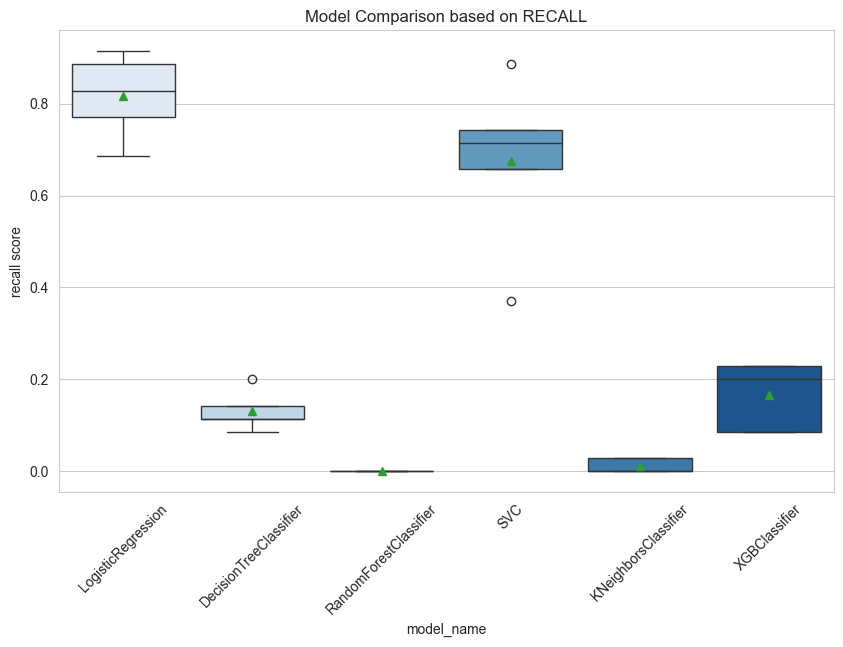


--- Model Ranking (Recall) ---
                            Mean       Std
model_name                                
LogisticRegression      0.817143  0.091696
SVC                     0.674286  0.189090
XGBClassifier           0.165714  0.073955
DecisionTreeClassifier  0.131429  0.043331
KNeighborsClassifier    0.011429  0.015649
RandomForestClassifier  0.000000  0.000000


In [65]:
models = [
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    SVC(probability=True, class_weight='balanced', random_state=RANDOM_STATE),
    KNeighborsClassifier(), 
    # XGBoost: scale_pos_weight ~ (Total Neg / Total Pos) ~ 19
    XGBClassifier(scale_pos_weight=19, eval_metric='logloss', random_state=RANDOM_STATE) 
]

def generate_baseline_results(models, X, y, metrics='recall', cv=5):
    # StratifiedKFold đảm bảo tỉ lệ Stroke trong các fold đều nhau
    kfold = StratifiedKFold(n_splits=cv, shuffle=True, random_state=RANDOM_STATE)
    entries = []
    
    print(f">> Benchmarking Models using {metrics.upper()} score...")
    
    for model in models:
        model_name = model.__class__.__name__
        # Thực hiện Cross-Validation
        scores = cross_val_score(model, X, y, scoring=metrics, cv=kfold)
        
        # Lưu lại từng fold score để vẽ biểu đồ
        for fold_idx, score in enumerate(scores):
            entries.append((model_name, fold_idx, score))
    
    # Tạo DataFrame kết quả
    cv_df = pd.DataFrame(entries, columns=['model_name', 'fold_id', 'score'])
    
    # 1. Vẽ biểu đồ Boxplot
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='model_name', y='score', data=cv_df, palette='Blues', showmeans=True)
    plt.title(f'Model Comparison based on {metrics.upper()}')
    plt.xticks(rotation=45)
    plt.ylabel(f'{metrics} score')
    plt.show()
    
    # 2. Tổng hợp kết quả Mean & Std
    mean = cv_df.groupby('model_name')['score'].mean()
    std = cv_df.groupby('model_name')['score'].std()
    
    result_table = pd.concat([mean, std], axis=1)
    result_table.columns = ['Mean', 'Std']
    return result_table.sort_values(by='Mean', ascending=False)

# --- THỰC THI BENCHMARK ---
# Metric 'recall' là quan trọng nhất để không bỏ sót bệnh
benchmark_results = generate_baseline_results(models, X_train_processed, y_train, metrics='recall')
print("\n--- Model Ranking (Recall) ---")
print(benchmark_results)

### ***5) Model Tuning & Final Result***
### ***5.1. Training Final Model***

In [66]:
final_model = LogisticRegression(
    max_iter=1000, 
    class_weight='balanced',
    random_state=RANDOM_STATE
)

final_model.fit(X_train_processed, y_train)

print("Training complete.")

Training complete.


### ***5.2. Predict with X_val***

--- Classification Report (Val - Default) ---
              precision    recall  f1-score   support

           0       0.98      0.71      0.82       728
           1       0.12      0.76      0.20        37

    accuracy                           0.71       765
   macro avg       0.55      0.73      0.51       765
weighted avg       0.94      0.71      0.79       765

ROC-AUC Score: 0.8015


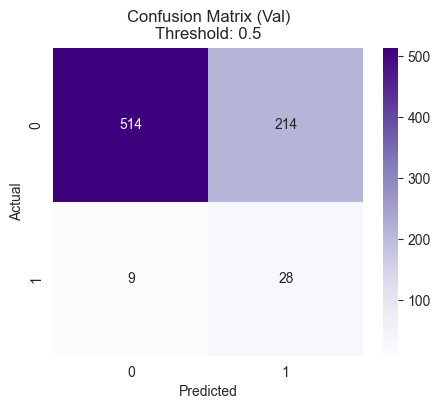

In [67]:
y_val_pred = final_model.predict(X_val_processed)
y_val_proba = final_model.predict_proba(X_val_processed)[:, 1]

print("--- Classification Report (Val - Default) ---")
print(classification_report(y_val, y_val_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_val, y_val_proba):.4f}")

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_val, y_val_pred), annot=True, fmt='d', cmap='Purples')
plt.title('Confusion Matrix (Val)\nThreshold: 0.5')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

### ***5.3 Optimize Threshold***

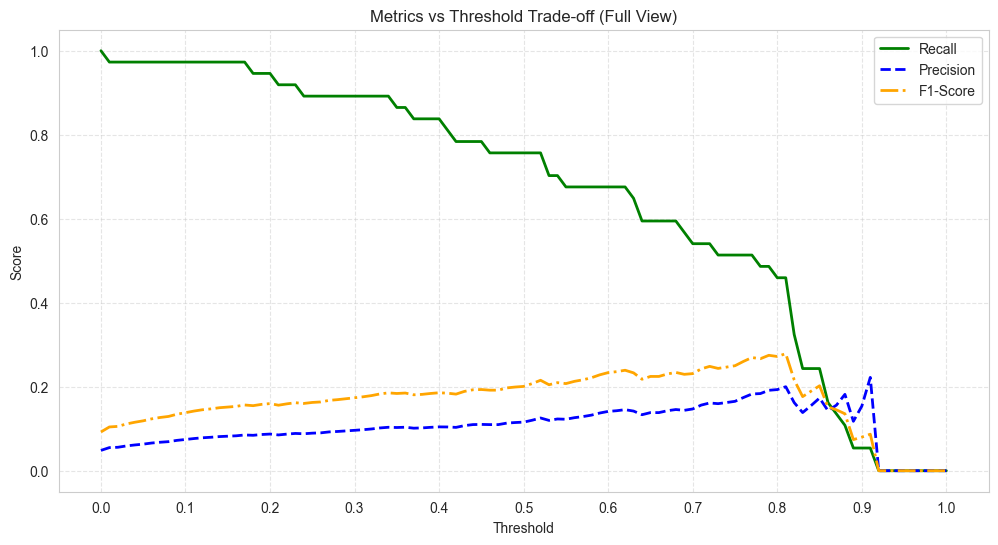

In [68]:
thresholds = np.arange(0.0, 1.01, 0.01)
recalls = []
precisions = []
f1_scores = []

for t in thresholds:
    y_pred_t = (y_val_proba >= t).astype(int)
    recalls.append(recall_score(y_val, y_pred_t, zero_division=0))
    precisions.append(precision_score(y_val, y_pred_t, zero_division=0))
    f1_scores.append(f1_score(y_val, y_pred_t, zero_division=0))

# 2. Vẽ biểu đồ toàn cảnh
plt.figure(figsize=(12, 6))
plt.plot(thresholds, recalls, label='Recall', color='green', linewidth=2)
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2, linestyle='--')
plt.plot(thresholds, f1_scores, label='F1-Score', color='orange', linewidth=2, linestyle='-.')

plt.title('Metrics vs Threshold Trade-off (Full View)')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.xticks(np.arange(0, 1.1, 0.1))
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.show()

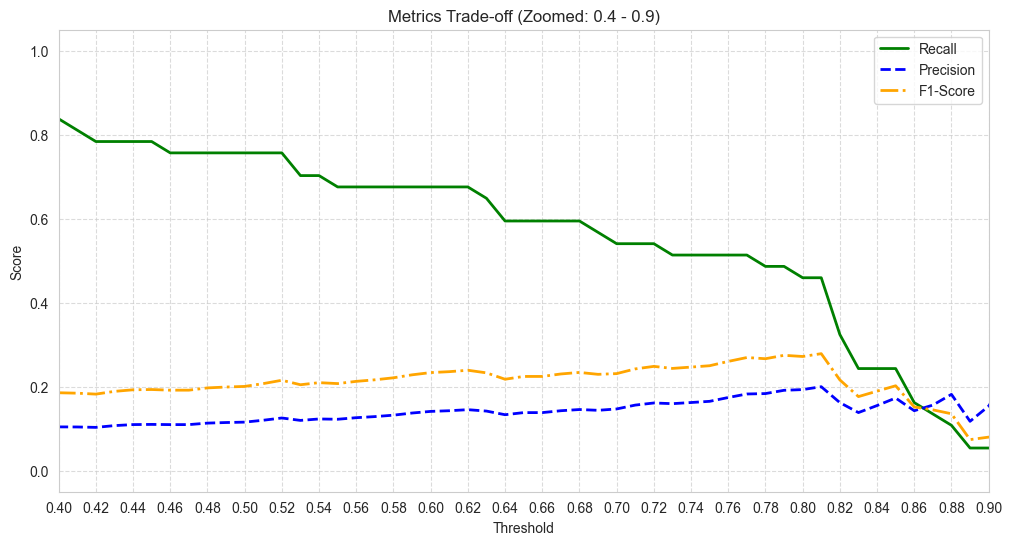

In [69]:
# --- CẤU HÌNH KHOẢNG ZOOM ---
ZOOM_START = 0.40  # Bắt đầu
ZOOM_END   = 0.90  # Kết thúc
# ----------------------------

plt.figure(figsize=(12, 6))
plt.plot(thresholds, recalls, label='Recall', color='green', linewidth=2)
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2, linestyle='--')
plt.plot(thresholds, f1_scores, label='F1-Score', color='orange', linewidth=2, linestyle='-.')

# Thiết lập giới hạn trục X để phóng to
plt.xlim(ZOOM_START, ZOOM_END)

# Chia vạch nhỏ hơn (mỗi 0.02) để dễ đọc số
plt.xticks(np.arange(ZOOM_START, ZOOM_END + 0.01, 0.02))

plt.title(f'Metrics Trade-off (Zoomed: {ZOOM_START} - {ZOOM_END})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.grid(True, which='both', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

>> Applying Selected Threshold (0.68) on TEST set...

Recall:    0.7297
Precision: 0.2045
ROC-AUC:   0.8221
------------------------------
              precision    recall  f1-score   support

           0       0.98      0.86      0.92       730
           1       0.20      0.73      0.32        37

    accuracy                           0.85       767
   macro avg       0.59      0.79      0.62       767
weighted avg       0.95      0.85      0.89       767



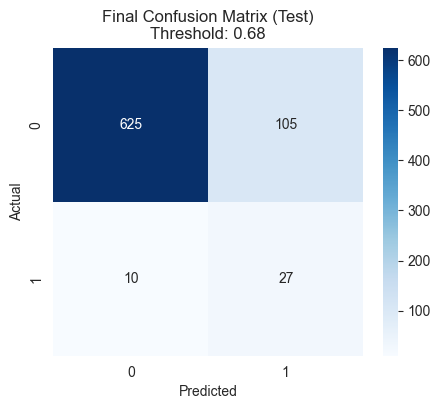

In [77]:
# ============================================================
# 5.4. FINAL EVALUATION ON TEST SET
# ============================================================

# --- NHẬP NGƯỠNG BẠN CHỌN TỪ BIỂU ĐỒ ZOOM ---
MY_THRESHOLD = 0.68
# --------------------------------------------

print(f">> Applying Selected Threshold ({MY_THRESHOLD}) on TEST set...")

# 1. Lấy xác suất trên tập TEST (Dữ liệu mới hoàn toàn)
y_test_proba = final_model.predict_proba(X_test_processed)[:, 1]

# 2. Áp dụng ngưỡng để ra quyết định
y_test_final = (y_test_proba >= MY_THRESHOLD).astype(int)

# 3. Báo cáo kết quả cuối cùng
print("\n" + "="*50)
print("="*50)

print(f"Recall:    {recall_score(y_test, y_test_final):.4f}")
print(f"Precision: {precision_score(y_test, y_test_final):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.4f}")
print("-" * 30)
print(classification_report(y_test, y_test_final))

# 4. Vẽ Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_test_final), annot=True, fmt='d', cmap='Blues')
plt.title(f'Final Confusion Matrix (Test)\nThreshold: {MY_THRESHOLD}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()